## Flipping a Coin
Let $n$ is the number of tossings and $m$ is the number of heads. We do not know if the coin is biased or not. Assume, that its probability mass function is $p_n(m)=C_n^m \theta^m (1-\theta)^{n-m},$ where $\theta$ is the probability of a head in one tossing.

In [1]:
import scipy.special as sc
sc.beta(37, 291)

np.float64(2.8292706458352143e-51)

In [ ]:
sc.beta(20, 142)*sc.beta(18, 150)

2.7407863693646133e-52

In [ ]:
sc.beta(31, 185)*sc.beta(7, 107)

4.713070570629082e-51

In [ ]:
sc.beta(20, 133)*sc.beta(1, 10)*sc.beta(12, 53)*sc.beta(7, 98)

1.770049401529901e-52

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import scipy.integrate as integrate

In [3]:
def likelihood(m,n,theta):
    return stats.binom(n, theta).pmf(m) #theta**m*(1-theta)**(n-m)

It is more probable that $\theta$ is close to $\frac{1}{2}.$ Introduce the apiori probability

In [4]:
a = 8
def prior(theta):
    return stats.beta(a,a).pdf(theta)

Also we will need the normalization constant, i.e., the denominator in the Bayesian formula $f(\theta|m,n)=\dfrac{f(\theta)p(m,n|\theta)}{p(m,n)}.$ Where $p(m,n)=\int\limits_0^1 p(m,n|\theta)d\theta.$ (We denote by $f$ the Probability Density Function for continuous random variables and by $p$ Probability Mass Function for discret variables.)

In [5]:
def evidence(m,n):
    result = integrate.quad(lambda x: prior(x)*likelihood(m,n,x), 0, 1)
    return result[0]

Define the posterior probability

In [6]:
def posterior(theta,m,n):
    return stats.beta(a+m,a+n-m).pdf(theta) #prior(theta)*likelihood(m,n,theta)/evidence(m,n)

Possible values of $\theta$

In [7]:
theta = np.linspace(0, 1, 100) #the possible values of theta

Number of tosses and heads

In [21]:
n = 1000
m = 400

The optimal value of $\theta$

In [22]:
amax = np.argmax(posterior(theta,m,n))
theta_opt = theta[amax]

In order to calculate the HPD (heighest probability distance), notice that posterior has beta distribution

In [23]:
a1 = stats.beta.ppf(0.25,a+m,a+n-m)
a2 = stats.beta.ppf(0.75,a+m,a+n-m)
print('[{0:.3f},{1:.3f}]'.format(a1,a2))

[0.391,0.412]


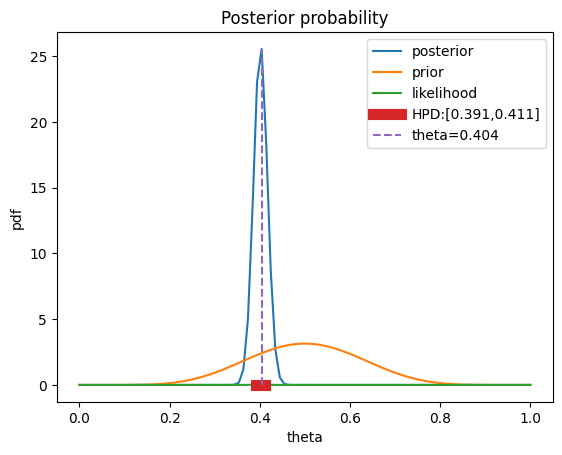

In [24]:
post = posterior(theta,m,n)
pr = prior(theta)
like = likelihood(m,n,theta)
#b = stats.beta(8+m,8+n-m).pdf(grid)
plt.plot(theta,post, label='posterior')
plt.plot(theta,pr, label='prior')
plt.plot(theta,like, label='likelihood')
#plt.plot(grid,post1)
#plt.plot(grid,b)
plt.plot([a1,a2],[0,0], linewidth=8, label='HPD:['+str(a1)[:5]+','+str(a2)[:5]+']')
plt.plot([theta_opt,theta_opt],[0,posterior(theta_opt,m,n)], linestyle='--', label='theta='+str(theta_opt)[:5])
plt.legend()
plt.title('Posterior probability'); plt.xlabel('theta'); plt.ylabel('pdf')
plt.show()

In [ ]:
np.argmax(post), np.argmax(like)

(np.int64(62), np.int64(79))

In [ ]:
n1 = 5
p = []
for m1 in range(n1+1):
    res = integrate.quad(lambda x: stats.beta.pdf(x,a+m,a+n-m)*likelihood(m1,n1,x), 0, 1)
    p.append(res[0])
#p=p/np.sum(p)
p

[0.060123784261715316,
 0.20041261420571777,
 0.30651340996168597,
 0.2681992337164753,
 0.13409961685823768,
 0.03065134099616862]

In [ ]:
np.sum(p)

1.0000000000000002

In [ ]:
t = np.random.beta(8+m,8+n-m,1000)

In [ ]:
n = 8
res=[]
for i in range(len(t)):
    res.append(np.random.binomial(n, t[i]))

In [ ]:
np.mean(res)

4.275

{'whiskers': [<matplotlib.lines.Line2D at 0x2139e3f7148>,
 'caps': [<matplotlib.lines.Line2D at 0x2139e3f7f48>,
 'boxes': [<matplotlib.lines.Line2D at 0x2139e3f1f88>],
 'medians': [<matplotlib.lines.Line2D at 0x2138d2864c8>],
 'fliers': [<matplotlib.lines.Line2D at 0x2139e454ec8>],
 'means': []}

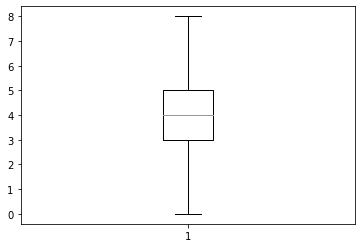

In [ ]:
plt.boxplot(res)